# Тема 5. Распределения ДСВ
---
Найдём закон распределения, $M(X)$, $D(X)$, $\sigma(X)$, моду и построим графики.

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## 1. Биномиальное распределение
> Марсик 10 раз пытается поймать игрушку. Вероятность успеха — 0,4. Попытки независимы. $X$ — число удачных попыток.

$P(X=k)=C_{10}^k p^k(1-p)^{10-k}$

$M(X)=np$, $D(X)=np(1-p)$, $Mo=4$.

 x  P(X=x)
 0 0.00605
 1 0.04031
 2 0.12093
 3 0.21499
 4 0.25082
 5 0.20066
 6 0.11148
 7 0.04247
 8 0.01062
 9 0.00157
10 0.00010
Сумма: 1.0
M(X) = 4.0
D(X) = 2.4
sigma = 1.5492
Mo = 4


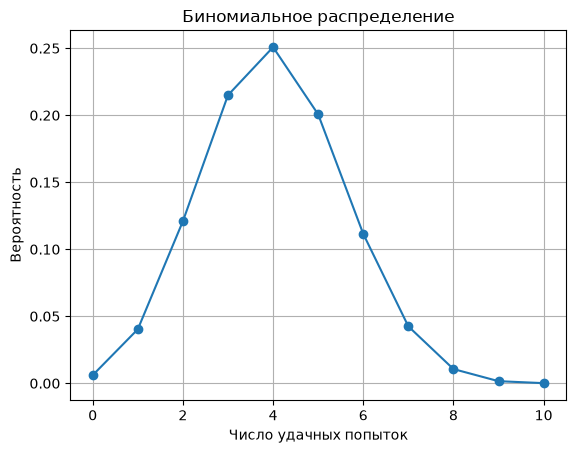

In [3]:
n = 10
p = 0.4
x = np.arange(n + 1)
prob = stats.binom.pmf(x, n, p)

print(pd.DataFrame({'x': x, 'P(X=x)': np.round(prob, 5)}).to_string(index=False))
print('Сумма:', round(prob.sum(), 5))
print('M(X) =', round(n * p, 4))
print('D(X) =', round(n * p * (1 - p), 4))
print('sigma =', round(math.sqrt(n * p * (1 - p)), 4))
print('Mo =', x[np.argmax(prob)])

plt.plot(x, prob, marker='o')
plt.title('Биномиальное распределение')
plt.xlabel('Число удачных попыток')
plt.ylabel('Вероятность')
plt.grid()
plt.show()

## 2. Распределение Пуассона
> За час гонки Формулы-1 происходит в среднем 2,5 обгона. $X$ — число обгонов за час (закон Пуассона).

$P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!}$

$M(X)=D(X)=\lambda$, $Mo=2$.

 x  P(X=x)
 0 0.08208
 1 0.20521
 2 0.25652
 3 0.21376
 4 0.13360
 5 0.06680
 6 0.02783
 7 0.00994
 8 0.00311
 9 0.00086
10 0.00022
11 0.00005
12 0.00001
Сумма на 0..12: 1.0
Хвост: 2e-06
M(X) = 2.5
D(X) = 2.5
sigma = 1.5811
Mo = 2


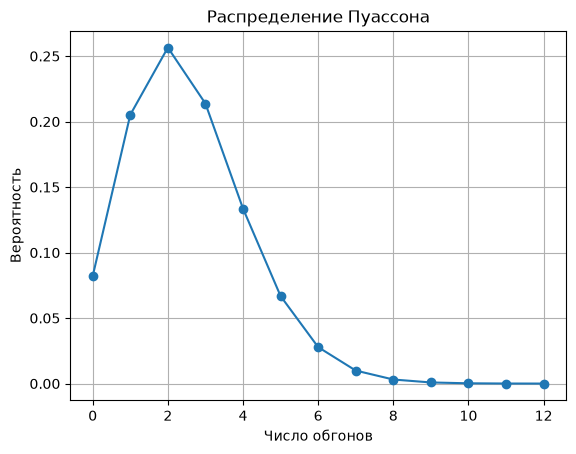

In [4]:
lam = 2.5
x = np.arange(0, 13)
prob = stats.poisson.pmf(x, lam)

print(pd.DataFrame({'x': x, 'P(X=x)': np.round(prob, 5)}).to_string(index=False))
print('Сумма на 0..12:', round(prob.sum(), 5))
print('Хвост:', round(stats.poisson.sf(12, lam), 6))
print('M(X) =', lam)
print('D(X) =', lam)
print('sigma =', round(math.sqrt(lam), 4))
print('Mo =', math.floor(lam))

plt.plot(x, prob, marker='o')
plt.title('Распределение Пуассона')
plt.xlabel('Число обгонов')
plt.ylabel('Вероятность')
plt.grid()
plt.show()

## 3. Геометрическое распределение
> Марсик пытается поймать мячик. Вероятность успеха — 0,35. Попытки независимы. $X$ — номер первой удачной попытки.

$P(X=k)=(1-p)^{k-1}p$

$M(X)=\frac1p$, $D(X)=\frac{1-p}{p^2}$, $Mo=1$.

 x  P(X=x)
 1 0.35000
 2 0.22750
 3 0.14788
 4 0.09612
 5 0.06248
 6 0.04061
 7 0.02640
 8 0.01716
 9 0.01115
10 0.00725
11 0.00471
12 0.00306
13 0.00199
14 0.00129
15 0.00084
16 0.00055
17 0.00036
18 0.00023
19 0.00015
20 0.00010
Сумма на 1..20: 0.99982
Хвост: 0.000181
M(X) = 2.8571
D(X) = 5.3061
sigma = 2.3035
Mo = 1


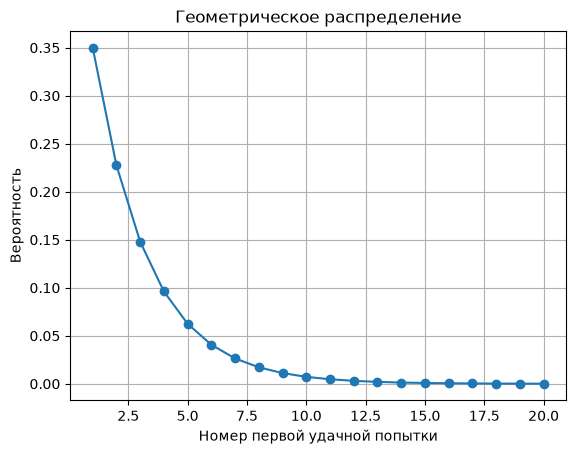

In [5]:
p = 0.35
x = np.arange(1, 21)
prob = stats.geom.pmf(x, p)

print(pd.DataFrame({'x': x, 'P(X=x)': np.round(prob, 5)}).to_string(index=False))
print('Сумма на 1..20:', round(prob.sum(), 5))
print('Хвост:', round(stats.geom.sf(20, p), 6))
print('M(X) =', round(1 / p, 4))
print('D(X) =', round((1 - p) / p ** 2, 4))
print('sigma =', round(math.sqrt(1 - p) / p, 4))
print('Mo =', 1)

plt.plot(x, prob, marker='o')
plt.title('Геометрическое распределение')
plt.xlabel('Номер первой удачной попытки')
plt.ylabel('Вероятность')
plt.grid()
plt.show()

## 4. Гипергеометрическое распределение
> Из 18 карточек с болидами Формулы-1 на 6 изображён Red Bull. Берём 5 карточек без возвращения. $X$ — число карточек Red Bull.

$P(X=k)=\frac{C_6^k C_{12}^{5-k}}{C_{18}^5}$

$M(X)=n\frac{K}{N}$, $D(X)=n\frac{K}{N}(1-\frac{K}{N})\frac{N-n}{N-1}$.

 x  P(X=x)
 0 0.09244
 1 0.34664
 2 0.38515
 3 0.15406
 4 0.02101
 5 0.00070
Сумма: 1.0
M(X) = 1.6667
D(X) = 0.8497
sigma = 0.9218
Mo = 2


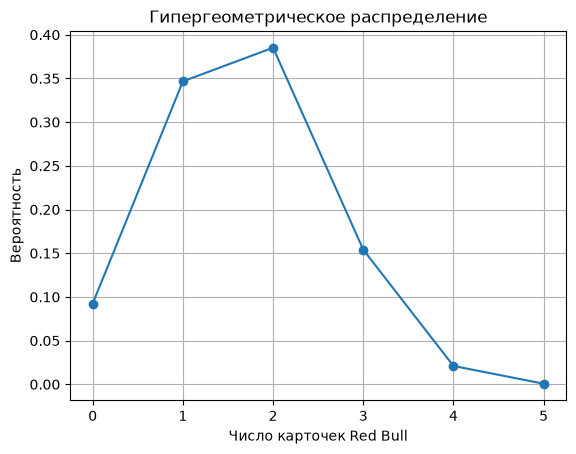

In [6]:
N = 18
K = 6
n = 5
x = np.arange(0, min(K, n) + 1)
prob = stats.hypergeom.pmf(x, N, K, n)

mean = n * K / N
variance = n * (K / N) * (1 - K / N) * (N - n) / (N - 1)

print(pd.DataFrame({'x': x, 'P(X=x)': np.round(prob, 5)}).to_string(index=False))
print('Сумма:', round(prob.sum(), 5))
print('M(X) =', round(mean, 4))
print('D(X) =', round(variance, 4))
print('sigma =', round(math.sqrt(variance), 4))
print('Mo =', x[np.argmax(prob)])

plt.plot(x, prob, marker='o')
plt.title('Гипергеометрическое распределение')
plt.xlabel('Число карточек Red Bull')
plt.ylabel('Вероятность')
plt.grid()
plt.show()